# F5 – Giám sát sức khỏe điểm đo AADT (4 mức phân tích)
Câu hỏi xuyên suốt: **điểm đo nào có số liệu đáng nghi, và nên kiểm tra điểm nào trước?**

- Bước 0: cấu hình
- Bước 1: nạp và chuẩn hóa dữ liệu
- Bước 2: lọc điểm đo theo audit / độ dài chuỗi
- Bước 3: Mức 1 – Descriptive
- Bước 4–5: Mức 2 – Diagnostic
- Bước 6–7: Mức 3 – Predictive
- Bước 8: Mức 4 – Prescriptive
- Bước 9: xuất kết quả

## Bước 0. Cấu hình
**Việc cần làm:** đối chiếu `COL` với `DATA_DICTIONARY.md`. Tên cột dưới đây là giả định.

In [ ]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

DATA_PATH = "../../harmonized_traffic_data/traffic_clean.parquet"
AUDIT_PATH = "../../outputs/temporal/city_temporal_audit_35_cities.csv"   # tùy chọn; không có file thì bỏ qua
OUT_DIR = Path("outputs/f5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

COL = dict(
    city="city", country="country", year="year",
    loc="location_id", loc_kind="location_id_kind",
    direction="direction", metric="metric_type",
    aadt="value",                       # giá trị lưu lượng
    data_kind="data_kind", flow_scope="flow_scope",
    flags="quality_flags", ml_ok="ml_label_ok",
    road="osm_type",                    # dùng làm cấp đường
    n_valid="n_valid_days", n_exp="n_expected_days",
    lon="lon", lat="lat",
)

# Bộ lọc tùy chọn (None = giữ tất cả). Điền sau khi xem các bảng đếm ở Bước 1.
METRICS_KEEP = None        # ví dụ ["AADT"]
DATA_KIND_KEEP = None      # ví dụ ["measured"]
FLOW_SCOPE_KEEP = None
LOC_KIND_EXCLUDE = []      # location_id_kind nào không ổn định giữa các năm thì liệt kê vào đây

# None = tự dò ở Bước 1; hoặc đặt tay, ví dụ [] hoặc ["flow_scope"]
KEY_EXTRA = None

MIN_YEARS = 4            # điểm đo phải có ít nhất ngần này năm
Z_THR = 3.0              # ngưỡng |z| để coi là bất thường
MIN_GROUP = 20           # nhóm (thành phố, metric, năm) tối thiểu để tính z
K_LIST = [10, 20, 50]    # k cho precision@k
EXCLUDE_LABEL_YEARS = [] # ví dụ [2020, 2021]: bỏ khỏi tập huấn luyện các nhãn rơi vào năm này
SEED = 42

## Bước 1. Nạp và chuẩn hóa dữ liệu

In [3]:
import pyarrow.parquet as pq

names = pq.ParquetFile(DATA_PATH).schema_arrow.names
for k, c in list(COL.items()):
    if c is not None and c not in names:
        print(f"[!] Không thấy cột '{c}' cho '{k}', bỏ qua.")
        COL[k] = None
assert all(COL[k] for k in ("city", "year", "loc", "aadt")), "Thiếu cột bắt buộc, sửa COL ở Bước 0."

raw = pd.read_parquet(DATA_PATH, columns=sorted({c for c in COL.values() if c}))
print("Kích thước:", raw.shape)

# Các bảng đếm để quyết định bộ lọc
for k in ("metric", "data_kind", "flow_scope", "loc_kind", "direction", "ml_ok"):
    if COL[k]:
        print(f"\n--- {COL[k]} ---")
        print(raw[COL[k]].astype(str).value_counts(dropna=False).head(15))
if COL["road"]:
    print(f"\n--- {COL['road']} (cấp đường) ---")
    print(raw[COL["road"]].astype(str).value_counts(dropna=False).head(15))
if COL["flags"]:
    print(f"\n--- {COL['flags']} (15 giá trị phổ biến nhất) ---")
    print(raw[COL["flags"]].astype(str).value_counts(dropna=False).head(15))


def to_flag(v):
    """Chuyển giá trị quality_flags (chuỗi, list, NaN, bool) thành True/False."""
    if v is None:
        return False
    if isinstance(v, (list, tuple, set, np.ndarray)):
        return len(v) > 0
    if isinstance(v, float) and np.isnan(v):
        return False
    if isinstance(v, str):
        return v.strip().lower() not in ("", "none", "nan", "[]", "ok", "false", "0")
    return bool(v)


def col_or(default, name):
    return raw[COL[name]] if COL[name] else default


n_rows = len(raw)
d = pd.DataFrame({
    "city": raw[COL["city"]].astype(str),
    "country": col_or("NA", "country"),
    "loc": raw[COL["loc"]].astype(str),
    "loc_kind": col_or("NA", "loc_kind").astype(str),
    "direction": col_or("all", "direction").astype(str),
    "metric": col_or("AADT", "metric").astype(str),
    "data_kind": col_or("NA", "data_kind").astype(str),
    "flow_scope": col_or("NA", "flow_scope").astype(str),
    "year": raw[COL["year"]].astype(int),
    "aadt": pd.to_numeric(raw[COL["aadt"]], errors="coerce"),
    "has_flag": raw[COL["flags"]].map(to_flag) if COL["flags"] else False,
    "ml_ok": raw[COL["ml_ok"]].astype(str) if COL["ml_ok"] else "NA",
    "road": raw[COL["road"]].astype(str) if COL["road"] else np.nan,
    "lon": pd.to_numeric(raw[COL["lon"]], errors="coerce") if COL["lon"] else np.nan,
    "lat": pd.to_numeric(raw[COL["lat"]], errors="coerce") if COL["lat"] else np.nan,
})
if COL["n_valid"] and COL["n_exp"]:
    nv = pd.to_numeric(raw[COL["n_valid"]], errors="coerce")
    ne = pd.to_numeric(raw[COL["n_exp"]], errors="coerce")
    d["coverage"] = (nv / ne.where(ne > 0)).clip(0, 1)     # tỷ lệ ngày đo hợp lệ
else:
    d["coverage"] = np.nan

# Bộ lọc tùy chọn
if METRICS_KEEP:     d = d[d["metric"].isin(METRICS_KEEP)]
if DATA_KIND_KEEP:   d = d[d["data_kind"].isin(DATA_KIND_KEEP)]
if FLOW_SCOPE_KEEP:  d = d[d["flow_scope"].isin(FLOW_SCOPE_KEEP)]
if LOC_KIND_EXCLUDE: d = d[~d["loc_kind"].isin(LOC_KIND_EXCLUDE)]

d = d[d["aadt"] > 0].dropna(subset=["aadt"])
print(f"\nGiữ {len(d)} / {n_rows} dòng sau khi lọc và bỏ giá trị rỗng hoặc <= 0")

# Khóa điểm đo. Nếu khóa cơ bản bị trùng thì dò xem thêm cột nào thì hết trùng.
BASE_KEY = ["city", "loc", "direction", "metric"]


def n_dups(key):
    return int(d.duplicated(key + ["year"]).sum())


if KEY_EXTRA is None:
    KEY_EXTRA = []
    base = n_dups(BASE_KEY)
    print("Dòng trùng với khóa cơ bản", BASE_KEY, "+ year:", base)
    if base > 0:
        cands = [c for c in ("data_kind", "flow_scope", "loc_kind") if d[c].nunique() > 1]
        found = False
        for r in range(1, len(cands) + 1):
            for combo in itertools.combinations(cands, r):
                if n_dups(BASE_KEY + list(combo)) == 0:
                    KEY_EXTRA, found = list(combo), True
                    break
            if found:
                break
        if found:
            print("-> Thêm", KEY_EXTRA, "vào khóa thì hết trùng. Có thể đặt cố định KEY_EXTRA ở Bước 0.")
        else:
            print("[!] Không cột nào làm hết trùng; sẽ lấy trung bình các dòng trùng. "
                  "Nên kiểm tra thủ công vì có thể đang trộn các loại số liệu khác nhau.")

KEY = BASE_KEY + KEY_EXTRA
print("KEY =", KEY)

if n_dups(KEY):
    print("Còn", n_dups(KEY), "dòng trùng, gộp bằng trung bình.")
    agg = {"aadt": "mean", "has_flag": "max", "coverage": "mean"}
    for c in d.columns:
        if c not in KEY + ["year"] and c not in agg:
            agg[c] = "first"
    d = d.groupby(KEY + ["year"], as_index=False).agg(agg)

print(d.groupby("city")["year"].agg(["min", "max"]).describe().loc[["min", "max"]])

Kích thước: (344193, 17)

--- metric_type ---
metric_type
AADT                     99152
AAWT                     70402
TR_AADT                  47430
2W_AADT                  33087
AADT_modelled            20183
AAWT_as_AADT             17740
TR_AAWT                  16632
TR_AAWT_as_AADT          15526
TR_AADT_modelled         10393
2W_AADT_modelled         10393
AADT_weekday_proxy        2695
TR_AADT_weekday_proxy      560
Name: count, dtype: int64

--- data_kind ---
data_kind
observed              234593
provider_estimated     65376
modelled               40969
proxy                   3255
Name: count, dtype: int64

--- flow_scope ---
flow_scope
whole_road            191545
one_direction          76426
both_on_oneway_way     58370
unknown                17852
Name: count, dtype: int64

--- location_id_kind ---
location_id_kind
source_id           313014
geometry_derived     31179
Name: count, dtype: int64

--- direction ---
direction
both            168900
unknown          99170
al

## Bước 2. Lọc điểm đo theo audit và độ dài chuỗi
Chỉ giữ điểm đo có thể theo dõi qua nhiều năm.

In [4]:
filter_log = []

audit_path = Path(AUDIT_PATH)
if audit_path.exists():
    audit = pd.read_csv(audit_path)
    print("Cột của file audit:", audit.columns.tolist())
    city_col = next((c for c in audit.columns if c.lower() in ("city", "city_name")), None)
    flag_cols = [c for c in ("not_for_trend", "id_not_stable_across_years") if c in audit.columns]
    if city_col and flag_cols:
        truthy = lambda s: s.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
        bad = np.zeros(len(audit), dtype=bool)
        for c in flag_cols:
            bad |= truthy(audit[c]).values
        excluded = set(audit.loc[bad, city_col].astype(str))
        d = d[~d["city"].isin(excluded)]
        filter_log.append(("audit: loại thành phố", len(excluded), d["city"].nunique()))
        print(f"Loại {len(excluded)} thành phố theo audit: {sorted(excluded)}")
    else:
        print("[!] Không nhận ra cột thành phố hoặc cột loại trừ trong audit. Bỏ qua bước này, "
              "hãy mở file và sửa 'city_col' / 'flag_cols'.")
else:
    print("Không có file audit, chỉ lọc theo độ dài chuỗi.")

n_years = d.groupby(KEY)["year"].transform("nunique")
before = d[KEY].drop_duplicates().shape[0]
d = d[n_years >= MIN_YEARS].copy()
after = d[KEY].drop_duplicates().shape[0]
filter_log.append((f"chuỗi >= {MIN_YEARS} năm", before - after, after))

print(pd.DataFrame(filter_log, columns=["bước lọc", "số bị loại", "còn lại"]))
print("Thành phố còn lại:", d["city"].nunique(), "| điểm đo:", after, "| dòng:", len(d))
pd.DataFrame(filter_log, columns=["buoc_loc", "so_bi_loai", "con_lai"]).to_csv(
    OUT_DIR / "filter_log.csv", index=False)

Cột của file audit: ['city', 'country', 'primary_metric', 'dominant_flow_scope', 'years_span', 'n_series', 'series_ge_5y', 'series_ge_8y', 'covid_19_22_full', 'tier', 'reason']
[!] Không nhận ra cột thành phố hoặc cột loại trừ trong audit. Bỏ qua bước này, hãy mở file và sửa 'city_col' / 'flag_cols'.
         bước lọc  số bị loại  còn lại
0  chuỗi >= 4 năm       91443    26585
Thành phố còn lại: 25 | điểm đo: 26585 | dòng: 190196


## Bước 3. Mức 1 – Descriptive
Chất lượng dữ liệu hiện ra sao?

year          2015   2016   2017   2018   2019   2020   2021   2022   2023  \
city                                                                         
Barcelona      NaN    NaN  0.019  0.019  0.031  0.029  0.066  0.059  0.061   
Birmingham   1.000  1.000  0.996  0.989  0.993  0.991  0.991  1.000  1.000   
Bordeaux       NaN    NaN    NaN    NaN  0.000  0.000  0.000  0.000  0.000   
Brno         0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000   
Cardiff      1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000   
Edinburgh    0.961  0.970  0.931  0.947  0.914  0.968  0.958  0.886  0.898   
Glasgow      0.802  0.833  0.829  0.848  0.854  0.883  0.884  0.924  0.884   
Hamburg      0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000   
Helsinki     0.018  0.018  0.018  0.018  0.018  0.018  0.018  0.018  0.018   
Lille        0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000   
Lisbon         NaN    NaN    NaN    NaN    NaN    NaN  0.000  0.

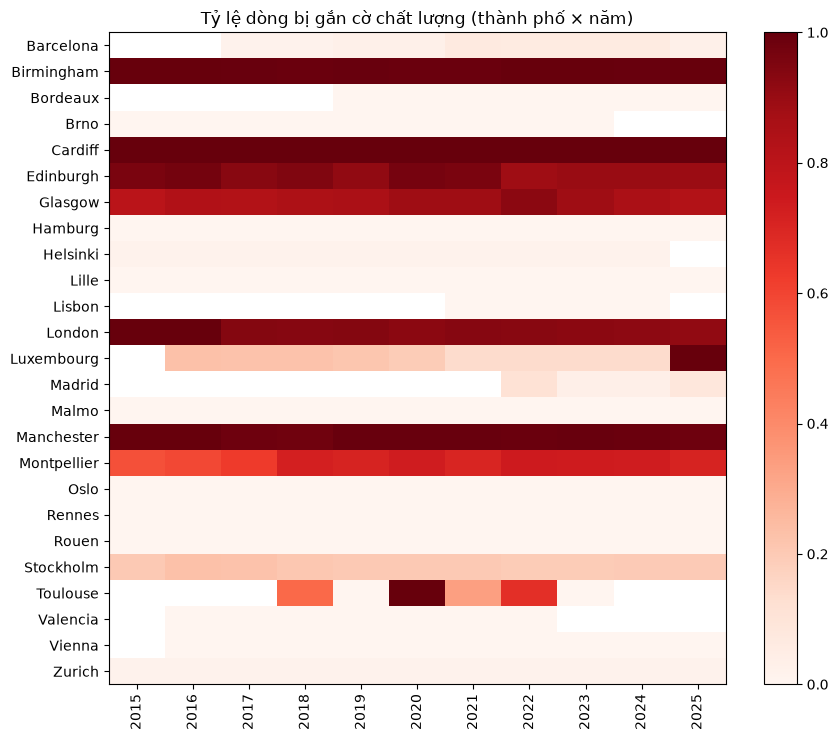


Phân bố số năm của điểm đo:
nunique
4     9983
5     2712
6      791
7     1281
8     1107
9     1091
10    1504
11    8116
Name: count, dtype: int64
Điểm đo bị đứt quãng: 2832 / 26585

Độ phủ ngày đo hợp lệ:
count    44488.0
mean       0.939
std        0.138
min        0.003
25%        0.967
50%        0.989
75%        0.997
max          1.0
Name: coverage, dtype: Float64
              mean  median  share_below_0.8
city                                       
Barcelona     <NA>    <NA>             <NA>
Birmingham    <NA>    <NA>             <NA>
Bordeaux      <NA>    <NA>             <NA>
Brno          <NA>    <NA>             <NA>
Cardiff       <NA>    <NA>             <NA>
Edinburgh     <NA>    <NA>             <NA>
Glasgow       <NA>    <NA>             <NA>
Hamburg       <NA>    <NA>             <NA>
Helsinki      <NA>    <NA>             <NA>
Lille         <NA>    <NA>             <NA>
Lisbon        0.45   0.401             0.75
London        <NA>    <NA>             <NA>
Luxembo

In [5]:
# 3a. Tỷ lệ dòng bị gắn cờ theo thành phố × năm
flag_rate = d.groupby(["city", "year"])["has_flag"].mean().unstack()
print(flag_rate.round(3))

fig, ax = plt.subplots(figsize=(9, max(3, 0.3 * len(flag_rate))))
im = ax.imshow(flag_rate.values, aspect="auto", cmap="Reds", vmin=0)
ax.set_xticks(range(flag_rate.shape[1]))
ax.set_xticklabels(flag_rate.columns, rotation=90)
ax.set_yticks(range(flag_rate.shape[0]))
ax.set_yticklabels(flag_rate.index)
ax.set_title("Tỷ lệ dòng bị gắn cờ chất lượng (thành phố × năm)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_flag_rate_heatmap.png", dpi=150)
plt.show()

# 3b. Độ đầy đủ chuỗi năm của từng điểm đo
span = d.groupby(KEY)["year"].agg(["min", "max", "nunique"])
span["gap"] = (span["max"] - span["min"] + 1) - span["nunique"]
print("\nPhân bố số năm của điểm đo:")
print(span["nunique"].value_counts().sort_index())
print("Điểm đo bị đứt quãng:", int((span["gap"] > 0).sum()), "/", len(span))

# 3c. Độ phủ ngày đo hợp lệ trong năm (n_valid_days / n_expected_days)
if d["coverage"].notna().any():
    print("\nĐộ phủ ngày đo hợp lệ:")
    print(d["coverage"].describe().round(3))
    cov_city = d.groupby("city")["coverage"].agg(["mean", "median", lambda s: (s < 0.8).mean()])
    cov_city.columns = ["mean", "median", "share_below_0.8"]
    print(cov_city.round(3))
    cov_city.to_csv(OUT_DIR / "coverage_by_city.csv")

# 3d. Số dòng và điểm đo theo thành phố
summary_city = d.groupby("city").agg(
    n_rows=("aadt", "size"),
    n_points=("loc", "nunique"),
    flag_rate=("has_flag", "mean"),
).sort_values("n_rows", ascending=False)
print(summary_city.round(3))
summary_city.to_csv(OUT_DIR / "descriptive_by_city.csv")
flag_rate.to_csv(OUT_DIR / "flag_rate_city_year.csv")

## Bước 4. Mức 2 – Diagnostic: tìm biến động bất thường
Δlog giá trị giữa hai năm liền kề, rồi z-score so với trung vị của cùng thành phố, cùng năm, cùng metric.
Cách này loại được cú sốc chung (ví dụ COVID) khỏi phần "bất thường riêng của điểm đo".

In [6]:
d = d.sort_values(KEY + ["year"]).reset_index(drop=True)


def G():
    return d.groupby(KEY, sort=False)


d["log_aadt"] = np.log(d["aadt"])
d["gap_prev"] = G()["year"].diff()
d["dlog"] = G()["log_aadt"].diff().where(d["gap_prev"] == 1)   # chỉ tính khi hai năm liền kề


def robust_z(x):
    med = x.median()
    mad = (x - med).abs().median()
    if not mad or np.isnan(mad):
        return pd.Series(np.nan, index=x.index)
    return 0.6745 * (x - med) / mad


grp = d.groupby(["city", "metric", "year"])
d["grp_n"] = grp["dlog"].transform("count")
d["z"] = grp["dlog"].transform(robust_z)
d.loc[d["grp_n"] < MIN_GROUP, "z"] = np.nan     # nhóm quá nhỏ thì trung vị không đáng tin


def mark_anomaly(thr):
    return np.where(d["z"].notna(), (d["z"].abs() > thr).astype(float), np.nan)


d["anomaly"] = mark_anomaly(Z_THR)

print(f"Dòng có z-score: {int(d['z'].notna().sum())} / {len(d)}")
print(f"Tỷ lệ bất thường (|z| > {Z_THR}): {np.nanmean(d['anomaly']):.4f}")

sens = pd.DataFrame({"thr": [2.5, 3.0, 3.5, 4.0]})
sens["rate"] = [np.nanmean(mark_anomaly(x)) for x in sens["thr"]]
sens["n"] = [int(np.nansum(mark_anomaly(x))) for x in sens["thr"]]
print("\nĐộ nhạy theo ngưỡng:")
print(sens)
sens.to_csv(OUT_DIR / "threshold_sensitivity.csv", index=False)

by_city = d.groupby("city")["anomaly"].agg(["mean", "sum", "count"]).sort_values("mean", ascending=False)
print("\nTỷ lệ bất thường theo thành phố:")
print(by_city.round(4).head(15))

Dòng có z-score: 154342 / 190196
Tỷ lệ bất thường (|z| > 3.0): 0.2273

Độ nhạy theo ngưỡng:
   thr      rate      n
0  2.5  0.246751  38084
1  3.0  0.227313  35084
2  3.5  0.213098  32890
3  4.0  0.201792  31145

Tỷ lệ bất thường theo thành phố:
               mean      sum  count
city                               
London       0.3527  21805.0  61818
Manchester   0.3425   1800.0   5256
Birmingham   0.3424   2278.0   6654
Cardiff      0.3184    766.0   2406
Edinburgh    0.2826    828.0   2930
Glasgow      0.2560   1501.0   5863
Montpellier  0.1169    311.0   2661
Valencia     0.1158     22.0    190
Rennes       0.1067    117.0   1097
Rouen        0.1065     33.0    310
Madrid       0.1051   2781.0  26463
Helsinki     0.1032    104.0   1008
Oslo         0.0926    298.0   3217
Barcelona    0.0871    179.0   2056
Stockholm    0.0852   1039.0  12196


## Bước 5. Mức 2 (tiếp): phân loại bất thường và đối chiếu với cờ chất lượng
Kết luận ở mức này chỉ nên viết là *"bất thường liên quan tới..."*, không viết là nguyên nhân.

Loại bất thường:
kind
persistent    20868
jump          14216
Name: count, dtype: int64

Bảng chéo cờ chất lượng × bất thường:
anomaly        0      1     All
has_flag                       
False      58451   8965   67416
True       60807  26119   86926
All       119258  35084  154342
Tỷ lệ bất thường chưa từng bị gắn cờ: 25.6%

Tỷ lệ bất thường theo ml_label_ok:
         mean  count
ml_ok               
False  0.1018  61937
True   0.3114  92405

Tỷ lệ bất thường theo độ phủ ngày đo:
                 mean  count
coverage                    
(-0.001, 0.5]  0.2957    531
(0.5, 0.8]     0.1714   1814
(0.8, 0.95]    0.1394   4145
(0.95, 1.0]    0.0838  27911

Tỷ lệ bất thường theo cấp đường:
                  mean  count
road                         
residential     0.3707  17238
unclassified    0.3374   2543
trunk           0.3326  23446
motorway        0.2943   5828
trunk_link      0.2699   1408
motorway_link   0.2668   3205
living_street   0.2542     59
None            0.2484   2355
se

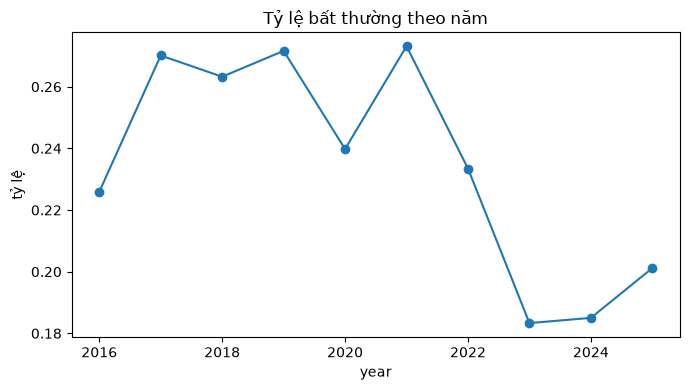

In [7]:
d["next_anom"] = G()["anomaly"].shift(-1)
d["prev_anom"] = G()["anomaly"].shift(1)
is_a = d["anomaly"] == 1
d["kind"] = np.select(
    [is_a & ((d["next_anom"] == 1) | (d["prev_anom"] == 1)), is_a],
    ["persistent", "jump"],
    default="",
)
print("Loại bất thường:")
print(d.loc[is_a, "kind"].value_counts())

# 5a. Cờ chất lượng có bắt được bất thường không?
scored = d[d["anomaly"].notna()]
ct = pd.crosstab(scored["has_flag"], scored["anomaly"].astype(int), margins=True)
print("\nBảng chéo cờ chất lượng × bất thường:")
print(ct)
share_unflagged = (scored.loc[scored["anomaly"] == 1, "has_flag"] == False).mean()
print(f"Tỷ lệ bất thường chưa từng bị gắn cờ: {share_unflagged:.1%}")
ct.to_csv(OUT_DIR / "crosstab_flag_anomaly.csv")

# 5b. ml_label_ok có liên quan tới bất thường không?
if COL["ml_ok"]:
    print("\nTỷ lệ bất thường theo ml_label_ok:")
    print(d.groupby("ml_ok")["anomaly"].agg(["mean", "count"]).round(4))

# 5c. Theo độ phủ ngày đo: độ phủ thấp có đi cùng bất thường không?
if d["coverage"].notna().any():
    bins = pd.cut(d["coverage"], [0, 0.5, 0.8, 0.95, 1.0], include_lowest=True)
    print("\nTỷ lệ bất thường theo độ phủ ngày đo:")
    print(d.groupby(bins)["anomaly"].agg(["mean", "count"]).round(4))

# 5d. Theo cấp đường (osm_type) và metric
if COL["road"]:
    print("\nTỷ lệ bất thường theo cấp đường:")
    print(d.groupby("road")["anomaly"].agg(["mean", "count"])
          .query("count >= 50").sort_values("mean", ascending=False).round(4).head(15))
print("\nTỷ lệ bất thường theo metric:")
print(d.groupby("metric")["anomaly"].agg(["mean", "count"]).round(4))

fig, ax = plt.subplots(figsize=(7, 4))
d.groupby("year")["anomaly"].mean().plot(marker="o", ax=ax)
ax.set_title("Tỷ lệ bất thường theo năm")
ax.set_ylabel("tỷ lệ")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_anomaly_rate_by_year.png", dpi=150)
plt.show()

In [8]:
d["chain_break"] = d["gap_prev"] > 1                      # năm này đứng sau một khoảng trống
sgn = np.sign(d["dlog"])
same_dir = (G()["dlog"].shift(1).pipe(np.sign) == sgn) | (G()["dlog"].shift(-1).pipe(np.sign) == sgn)
is_a = d["anomaly"] == 1
d["kind3"] = np.select(
    [is_a & same_dir & (d["dlog"] < 0), is_a & same_dir, is_a],
    ["gradual_decline", "gradual_rise", "jump"], default="")

## Bước 6. Mức 3 – Predictive: dựng bảng huấn luyện
Mỗi dòng là một điểm đo tại năm `t`. Mọi đặc trưng chỉ dùng thông tin từ năm `t` trở về trước.
Nhãn `y` = điểm đo bất thường ở năm `t+1`.

In [9]:
d["abs_z"] = d["z"].abs()

# Độ lệch chuẩn của dlog trong 3 điểm gần nhất (vectorized, nhanh hơn rolling theo nhóm)
s0 = d["dlog"].to_numpy()
s1 = G()["dlog"].shift(1).to_numpy()
s2 = G()["dlog"].shift(2).to_numpy()
M = np.column_stack([s0, s1, s2])
cnt = np.sum(~np.isnan(M), axis=1)
with np.errstate(all="ignore"):
    sd = np.nanstd(M, axis=1, ddof=1)
d["dlog_std3"] = np.where(cnt >= 2, sd, np.nan)

d["anom0"] = d["anomaly"].fillna(0)
d["n_anom_past"] = G()["anom0"].cumsum()           # gồm cả năm t, không gồm t+1
d["flag_int"] = d["has_flag"].astype(int)
d["n_flag_past"] = G()["flag_int"].cumsum()
d["n_years"] = G().cumcount() + 1
d["cov_drop"] = d["coverage"] - G()["coverage"].shift(1)   # độ phủ giảm so với năm trước

# Nhãn: bất thường ở năm kế tiếp, chỉ hợp lệ khi năm kế tiếp đúng là t+1
d["y"] = G()["anomaly"].shift(-1)
d["next_year"] = G()["year"].shift(-1)
d.loc[d["next_year"] != d["year"] + 1, "y"] = np.nan

d["importance"] = d.groupby(["city", "year"])["log_aadt"].rank(pct=True)

NUM = ["abs_z", "dlog", "dlog_std3", "n_anom_past", "n_flag_past", "n_years",
       "log_aadt", "flag_int", "coverage", "cov_drop"]
CAT = ["metric"] + (["road"] if COL["road"] else [])

f = d.dropna(subset=["y"]).copy()
f["y"] = f["y"].astype(int)
print("Số dòng có nhãn:", len(f), "| tỷ lệ nhãn dương:", round(f["y"].mean(), 4))
print(f.groupby("year")["y"].agg(["size", "sum", "mean"]).round(4))

Số dòng có nhãn: 154342 | tỷ lệ nhãn dương: 0.2273
       size   sum    mean
year                     
2015  11355  2565  0.2259
2016  12379  3344  0.2701
2017  13174  3468  0.2632
2018  13931  3784  0.2716
2019  13233  3173  0.2398
2020  12656  3457  0.2732
2021  12889  3009  0.2335
2022  21749  3987  0.1833
2023  21571  3991  0.1850
2024  21405  4306  0.2012


## Bước 7. Mức 3: chia theo thời gian, huấn luyện, đánh giá
Chia theo năm `t`, không chia ngẫu nhiên, để model không "nhìn thấy tương lai".

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

t_max = int(f["year"].max())
TEST_T, VAL_T, TRAIN_MAX = t_max, t_max - 1, t_max - 2

train = f[(f["year"] <= TRAIN_MAX) & ~((f["year"] + 1).isin(EXCLUDE_LABEL_YEARS))]
val = f[f["year"] == VAL_T]
test = f[f["year"] == TEST_T]
for name, part in (("train", train), ("val", val), ("test", test)):
    print(f"{name:5s}: {len(part):7d} dòng, {int(part['y'].sum()):5d} nhãn dương ({part['y'].mean():.3%})")
assert train["y"].nunique() == 2 and val["y"].sum() > 0 and test["y"].sum() > 0, \
    "Thiếu nhãn dương ở một tập. Hạ Z_THR hoặc MIN_GROUP ở Bước 0."


def make_pre(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="NA")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=30, sparse_output=False))]), CAT),
    ])


def prep(x):
    x = x[NUM + CAT].copy()
    for c in CAT:
        x[c] = x[c].astype("object")
    return x


models = {
    "logreg": Pipeline([("pre", make_pre(True)),
                        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
    "hgb": Pipeline([("pre", make_pre(False)),
                     ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_depth=4,
                                                            learning_rate=0.05, max_iter=300,
                                                            random_state=SEED))]),
}


def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.nanargmax(f1[:-1])])


def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(pr_auc=average_precision_score(y, p),
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                thr=thr)


rows = []
# Baseline: "năm t bất thường thì năm t+1 cũng bất thường"
rows.append({"model": "baseline", **evaluate(test["y"], test["anom0"].values, 0.5),
             "val_pr_auc": average_precision_score(val["y"], val["anom0"].values)})

preds = {}
for name, m in models.items():
    m.fit(prep(train), train["y"])
    p_val = m.predict_proba(prep(val))[:, 1]
    thr = best_threshold(val["y"], p_val)                 # chọn ngưỡng trên tập val
    p_test = m.predict_proba(prep(test))[:, 1]            # tập test chỉ dùng để đánh giá
    preds[name] = p_test
    rows.append({"model": name, **evaluate(test["y"], p_test, thr),
                 "val_pr_auc": average_precision_score(val["y"], p_val)})

res = pd.DataFrame(rows).set_index("model")
res["test_base_rate"] = test["y"].mean()
print(res.round(4))
res.to_csv(OUT_DIR / "model_results.csv")

BEST = res.drop(index="baseline")["val_pr_auc"].idxmax()   # chọn model theo val, không theo test
print("Model được chọn (theo PR-AUC trên val):", BEST)
test = test.assign(p=preds[BEST])

thr_best = res.loc[BEST, "thr"]
per_city = (test.assign(pred=(test["p"] >= thr_best).astype(int))
            .groupby("city")
            .apply(lambda g: pd.Series({
                "n": len(g), "n_pos": int(g["y"].sum()),
                "precision": precision_score(g["y"], g["pred"], zero_division=0),
                "recall": recall_score(g["y"], g["pred"], zero_division=0)})))
print(per_city.sort_values("n_pos", ascending=False).round(3).head(15))
per_city.to_csv(OUT_DIR / "test_by_city.csv")

train:  111366 dòng, 26787 nhãn dương (24.053%)
val  :   21571 dòng,  3991 nhãn dương (18.502%)
test :   21405 dòng,  4306 nhãn dương (20.117%)
          pr_auc  precision  recall     thr  val_pr_auc  test_base_rate
model                                                                  
baseline  0.3676     0.5420  0.4882  0.5000      0.3706          0.2012
logreg    0.5932     0.6099  0.5123  0.6109      0.6041          0.2012
hgb       0.6141     0.6689  0.4935  0.6508      0.6240          0.2012
Model được chọn (theo PR-AUC trên val): hgb
                  n   n_pos  precision  recall
city                                          
London       5925.0  2154.0      0.736   0.693
Madrid       8821.0  1081.0      0.329   0.104
Birmingham    609.0   244.0      0.640   0.496
Manchester    524.0   187.0      0.657   0.615
Glasgow       594.0   169.0      0.750   0.870
Stockholm    1321.0   121.0      0.522   0.198
Edinburgh     280.0    91.0      0.674   0.681
Cardiff       188.0    59.0  

## Bước 8. Mức 4 – Prescriptive: xếp hạng điểm đo cần kiểm tra
Điểm ưu tiên = xác suất bất thường × tầm quan trọng (hạng phần trăm của log giá trị trong thành phố).
So với: (a) chỉ dựa vào cờ chất lượng sẵn có, (b) chọn ngẫu nhiên.

    model_score  model_prob_only  existing_flag  random  lift_vs_random
k                                                                      
10        0.379            0.484          0.174   0.162           2.339
20        0.350            0.437          0.179   0.162           2.160
50        0.321            0.391          0.164   0.162           1.981


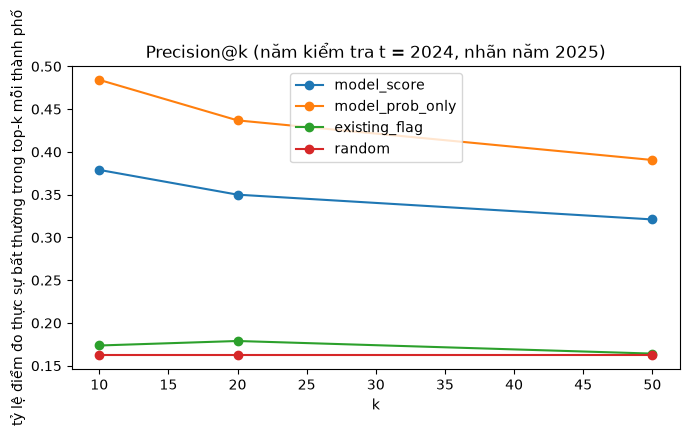

In [11]:
rng = np.random.default_rng(SEED)
test["score"] = test["p"] * test["importance"]
test["flag_score"] = test["flag_int"].astype(float)


def top_k(g, col, k):
    tmp = g.assign(_r=rng.random(len(g))).sort_values([col, "_r"], ascending=False)  # ngẫu nhiên khi hòa
    return tmp.head(k)


def pooled_precision_at_k(df_, col, k):
    hits = total = 0
    for _, g in df_.groupby("city"):
        top = top_k(g, col, k)
        hits += top["y"].sum()
        total += len(top)
    return hits / total if total else np.nan


rows = []
for k in K_LIST:
    exp_hits = exp_total = 0
    for _, g in test.groupby("city"):
        kk = min(k, len(g))
        exp_hits += kk * g["y"].mean()
        exp_total += kk
    rows.append({
        "k": k,
        "model_score": pooled_precision_at_k(test, "score", k),
        "model_prob_only": pooled_precision_at_k(test, "p", k),
        "existing_flag": pooled_precision_at_k(test, "flag_score", k),
        "random": exp_hits / exp_total,
    })
patk = pd.DataFrame(rows).set_index("k")
patk["lift_vs_random"] = patk["model_score"] / patk["random"]
print(patk.round(3))
patk.to_csv(OUT_DIR / "precision_at_k.csv")

fig, ax = plt.subplots(figsize=(7, 4))
patk[["model_score", "model_prob_only", "existing_flag", "random"]].plot(marker="o", ax=ax)
ax.set_title(f"Precision@k (năm kiểm tra t = {TEST_T}, nhãn năm {TEST_T + 1})")
ax.set_ylabel("tỷ lệ điểm đo thực sự bất thường trong top-k mỗi thành phố")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_precision_at_k.png", dpi=150)
plt.show()

In [12]:
d["severity"] = d.groupby(["city", "year"])["abs_z"].rank(pct=True).fillna(0)
test["score"] = test["p"] * test["severity"] * test["importance"]

KeyError: 'severity'

### Danh sách điểm đo cần kiểm tra cho năm tới
Chấm điểm các dòng của **năm cuối cùng trong dữ liệu** (chưa có nhãn) bằng model đã chọn.

In [ ]:
K_FINAL = 20
last_year = int(d["year"].max())
latest = d[d["year"] == last_year].copy()
latest["p"] = models[BEST].predict_proba(prep(latest))[:, 1]
latest["score"] = latest["p"] * latest["importance"]
latest["rank_in_city"] = latest.groupby("city")["score"].rank(ascending=False, method="first")

cols = ["city", "country", "loc", "direction", "metric", "road", "year", "aadt", "p", "score",
        "n_anom_past", "n_flag_past", "coverage", "lon", "lat", "rank_in_city"]
watchlist = (latest[latest["rank_in_city"] <= K_FINAL]
             .sort_values(["city", "rank_in_city"])[cols])
print(f"Danh sách điểm đo cần kiểm tra (dự báo cho năm {last_year + 1}):", len(watchlist), "dòng")
print(watchlist.head(15).round(4))

Danh sách điểm đo cần kiểm tra (dự báo cho năm 2026): 400 dòng
           city country       loc        direction metric          road  year  \
831   Barcelona   Spain  14-SMD-2         Trinitat   AADT         trunk  2025   
1415  Barcelona   Spain  39-SMD-1         Trinitat   AADT         trunk  2025   
1339  Barcelona   Spain  36-SMD-2        Llobregat   AADT         trunk  2025   
1324  Barcelona   Spain  36-SMD-1         Trinitat   AADT         trunk  2025   
1423  Barcelona   Spain  39-SMD-1         Trinitat   AAWT         trunk  2025   
839   Barcelona   Spain  14-SMD-2         Trinitat   AAWT         trunk  2025   
2876  Barcelona   Spain      8033            Besòs   AADT      tertiary  2025   
1347  Barcelona   Spain  36-SMD-2        Llobregat   AAWT         trunk  2025   
23    Barcelona   Spain  10-SMD-2         Trinitat   AADT         trunk  2025   
2881  Barcelona   Spain      8033            Besòs   AAWT      tertiary  2025   
163   Barcelona   Spain      1003          Ent

## Bước 9. Xuất kết quả

In [ ]:
watchlist.to_csv(OUT_DIR / "watchlist.csv", index=False)
d.to_parquet(OUT_DIR / "f5_scored_points.parquet", index=False)
print("Đã ghi vào", OUT_DIR.resolve())
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

Đã ghi vào /home/pthi35/code/Hust/2026_1/Intro DS/KHDL---G9/f5/outputs/f5
 - 01_flag_rate_heatmap.png
 - 02_anomaly_rate_by_year.png
 - 03_precision_at_k.png
 - coverage_by_city.csv
 - crosstab_flag_anomaly.csv
 - descriptive_by_city.csv
 - f5_scored_points.parquet
 - filter_log.csv
 - flag_rate_city_year.csv
 - model_results.csv
 - precision_at_k.csv
 - test_by_city.csv
 - threshold_sensitivity.csv
 - watchlist.csv
